#Total result

**학습 조건은 다양한 모델과 하이퍼파라미터, 그리고 일자와 앙상블에 사용하는 모델 수와 깊이를 고려하여 진행 [ 약 500개 데이터에서 상위 60개를 뽑아 아래와 같은 조건으로 데이터화 함**

ensemble_name : ensemble에 사용한 모델


---


models_in_ensemble : ensemble에 사용한
paramter

---


data_case

A.'neg', 'pos', 'calculate'

B.'neg', 'pos', 'calculate', 'trading'

C.'neg', 'pos', 'calculate', 'change'

D.'neg', 'pos', 'calculate', 'trading',
'change'



---

cap_method : 해당 일자에 해당하는 기업별 시가총액 사용 여부



---
scaler : minmax , standard 중 하나


---

time_steps : 사용할 일자



---

train_ratio , val_ratio : train,val set

**결과적으로 가장 좋은 성능은 ensemble을 사용했고, hybrid인 LSTM+GRU로 한 것과, LSTM+GRU+CNN에 결과가 가장 근접한 성과인 것을 확인할 수가 있음**

top_lstm_gru.head() [

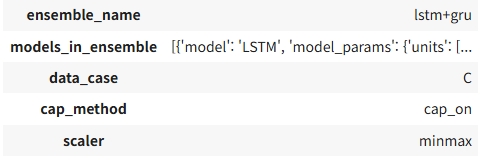

top_lstm_gru_cnn.head()

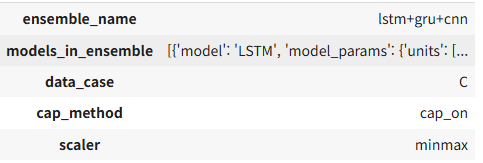

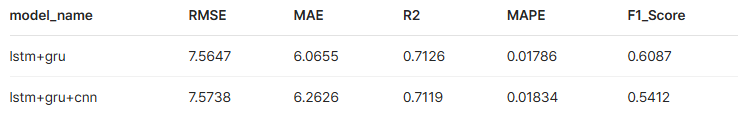

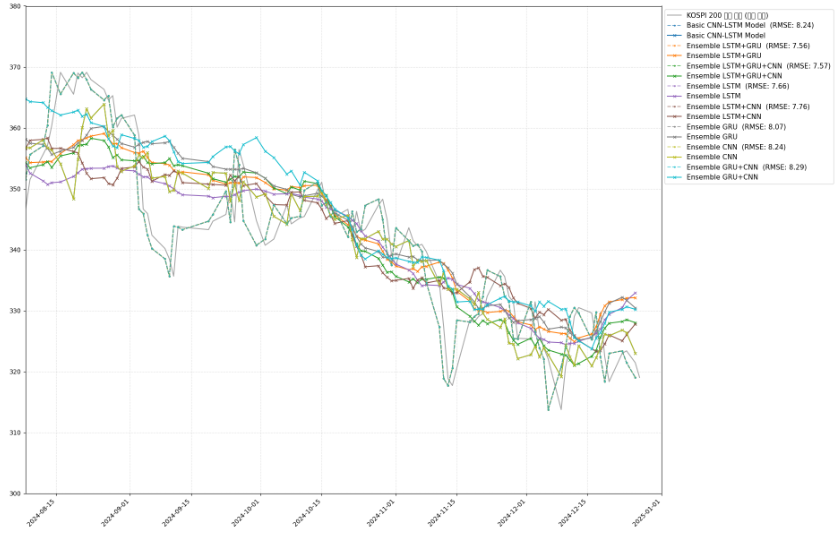

#Google drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#import

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    mean_absolute_percentage_error, f1_score, confusion_matrix, accuracy_score,
    precision_score, recall_score
)
import ast
import matplotlib.pyplot as plt

import warnings

#kospi200 dataset

In [ ]:
companies = [
    "Hyundai", "Kbfg", "Kia", "Lgchem", "Lgensol", "Naver", "PoscoHoldings",
    "SamsungBiologics", "Samsung", "Skhynix"
]

kospi_path = '/content/drive/MyDrive/dataset/kospi200_cleaned_data.csv'

df_kospi = pd.read_csv(kospi_path)
df_kospi['y'] = df_kospi['y'].astype(str)
df_kospi['m'] = df_kospi['m'].astype(str).str.zfill(2)
df_kospi['d'] = df_kospi['d'].astype(str).str.zfill(2)
df_kospi['date'] = pd.to_datetime(df_kospi['y'] + df_kospi['m'] + df_kospi['d'],format="%Y%m%d")
df_kospi = df_kospi[['date', 'closing price','change']]
df_kospi = df_kospi.sort_values('date').reset_index(drop=True)
df_kospi['target'] = df_kospi['closing price'].shift(-1)
df_kospi.dropna(inplace=True)

df_kospi.head()

,date,closing price,change,target
0,2022-01-27,348.58,-3.39,357.98
1,2022-01-28,357.98,2.70,361.60
2,2022-02-03,361.60,1.01,366.34
3,2022-02-04,366.34,1.31,362.92
4,2022-02-07,362.92,-0.93,363.48


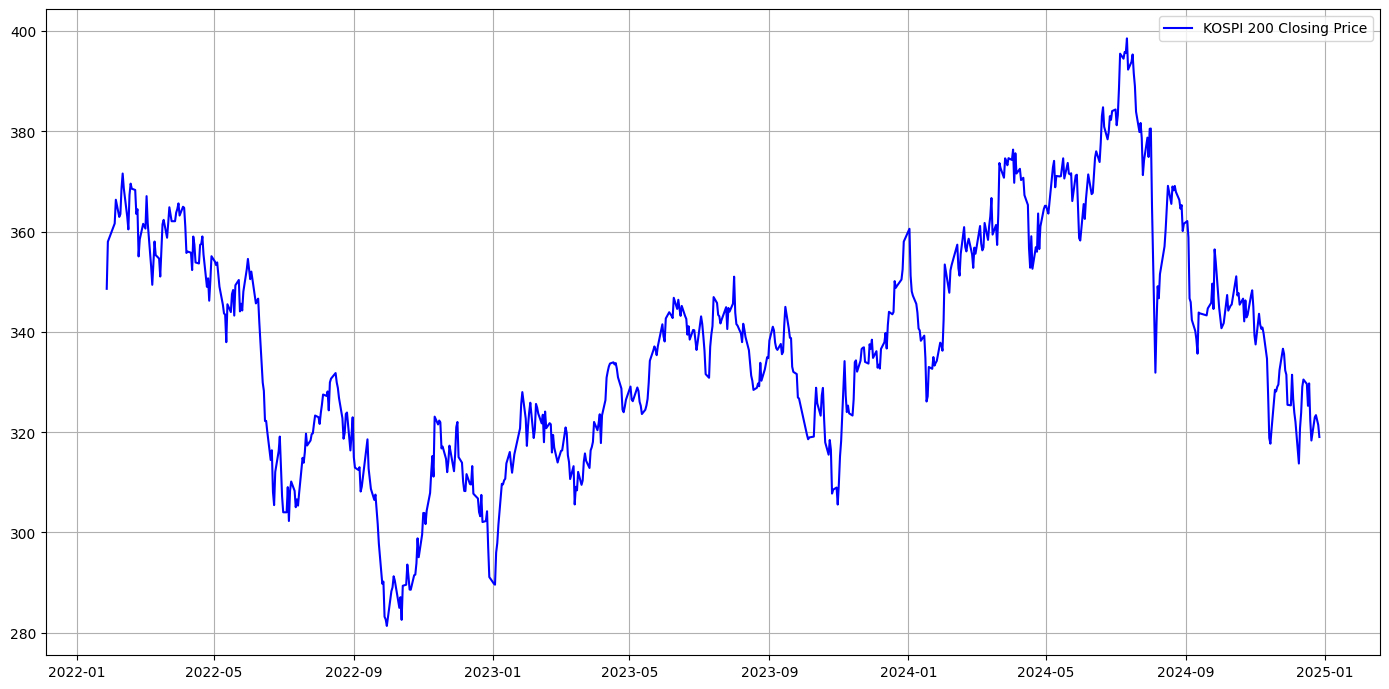

In [ ]:
plt.figure(figsize=(14, 7))
plt.plot(df_kospi['date'], df_kospi['closing price'], label='KOSPI 200 Closing Price', color='blue')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

#path and dataset

In [ ]:
basic_path = "/content/drive/MyDrive/share_drive/박박박사/여러가지_학습후_결과저장/individual_model_results.json"
ensemble_path = "/content/drive/MyDrive/share_drive/박박박사/여러가지_학습후_결과저장/ensemble_model_results.json"

In [ ]:
df_basic = pd.read_json(basic_path)
df_ensemble = pd.read_json(ensemble_path)

#prepare basic dataset

In [ ]:
df_basic['model'].unique().tolist()

['LSTM', 'GRU', 'CNN-LSTM']

In [ ]:
df_basic_LSTM = df_basic[df_basic['model'] == 'LSTM'].copy()
df_basic_GRU = df_basic[df_basic['model'] == 'GRU'].copy()
df_basic_CNN_LSTM = df_basic[df_basic['model'] == 'CNN-LSTM'].copy()

In [ ]:
df_basic_GRU['model_params'].value_counts()

,count
model_params,
"{'units': [100, 50, 25], 'dropouts': [0.30000000000000004, 0.15, 0.1]}",12
"{'units': [72, 36, 18], 'dropouts': [0.25, 0.19, 0.1]}",3


In [ ]:
df_basic_CNN_LSTM['val_ratio'].value_counts()

,count
val_ratio,
0.151,7
0.150,5


In [ ]:
df_basic_LSTM['model_params'].value_counts()

,count
model_params,
"{'units': [100, 50, 25], 'dropouts': [0.30000000000000004, 0.15, 0.1]}",19
"{'units': [72, 36, 18], 'dropouts': [0.25, 0.19, 0.1]}",14


**LSTM으로 학습했을 때 성능순으로 배열**

In [ ]:
pd.set_option('display.max_rows', 60)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 50)
df_basic_LSTM.head(1)

,model,model_params,time_step,train_ratio,val_ratio,data_case,cap_method,scaler,RMSE,MAE,R2,MAPE,F1_Score,y_true,y_pred,dates
0,LSTM,"{'units': [100, 50, 25], 'dropouts': [0.300000...",21,0.71,0.151,B,cap_on,minmax,7.379602,5.92637,0.726518,0.017408,0.637363,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[364.4466857910156, 363.67132568359375, 362.70...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."


In [ ]:
df_basic_LSTM.head()

,model,model_params,time_step,train_ratio,val_ratio,data_case,cap_method,scaler,RMSE,MAE,R2,MAPE,F1_Score,y_true,y_pred,dates
0,LSTM,"{'units': [100, 50, 25], 'dropouts': [0.300000...",21,0.71,0.151,B,cap_on,minmax,7.379602,5.926370,0.726518,0.017408,0.637363,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[364.4466857910156, 363.67132568359375, 362.70...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
1,LSTM,"{'units': [100, 50, 25], 'dropouts': [0.300000...",20,0.71,0.151,A,cap_on,minmax,7.726046,6.161696,0.700237,0.017884,0.568182,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[353.20013427734375, 351.6382141113281, 350.92...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
3,LSTM,"{'units': [100, 50, 25], 'dropouts': [0.300000...",21,0.71,0.151,D,cap_off,standard,8.005036,6.239520,0.678197,0.018216,0.523810,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[351.7541198730469, 350.73590087890625, 349.57...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
7,LSTM,"{'units': [72, 36, 18], 'dropouts': [0.25, 0.1...",20,0.71,0.151,A,cap_on,minmax,8.129925,6.608171,0.668078,0.019366,0.595745,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[358.6191711425781, 356.92681884765625, 355.76...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
10,LSTM,"{'units': [100, 50, 25], 'dropouts': [0.300000...",20,0.71,0.151,A,cap_on,standard,8.276276,6.645421,0.656020,0.019460,0.612245,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[355.08636474609375, 354.2019958496094, 354.01...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."


**GRU으로 학습했을 때 성능순으로 배열**

In [ ]:
df_basic_GRU.head()

,model,model_params,time_step,train_ratio,val_ratio,data_case,cap_method,scaler,RMSE,MAE,R2,MAPE,F1_Score,y_true,y_pred,dates
2,GRU,"{'units': [100, 50, 25], 'dropouts': [0.300000...",20,0.71,0.151,C,cap_on,minmax,7.731447,5.919069,0.699818,0.017460,0.556701,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[358.1682434082031, 357.97900390625, 358.88165...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
4,GRU,"{'units': [100, 50, 25], 'dropouts': [0.300000...",21,0.71,0.151,D,cap_on,minmax,8.014009,6.543716,0.677476,0.019268,0.555556,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[359.9114990234375, 360.4726257324219, 361.372...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
5,GRU,"{'units': [100, 50, 25], 'dropouts': [0.300000...",20,0.71,0.151,D,cap_on,minmax,8.018342,6.683029,0.677127,0.019638,0.547619,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[361.535400390625, 361.70709228515625, 362.323...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
6,GRU,"{'units': [100, 50, 25], 'dropouts': [0.300000...",20,0.71,0.151,C,cap_on,standard,8.081811,6.660576,0.671995,0.019634,0.450000,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[354.4963073730469, 354.7412414550781, 355.506...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
8,GRU,"{'units': [100, 50, 25], 'dropouts': [0.300000...",21,0.71,0.151,C,cap_on,standard,8.150581,6.735833,0.666389,0.019795,0.461538,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[351.2393798828125, 352.86993408203125, 354.24...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."


**CNN으로 학습했을 때 성능순으로 배열**

In [ ]:
df_basic_CNN_LSTM.head()

,model,model_params,time_step,train_ratio,val_ratio,data_case,cap_method,scaler,RMSE,MAE,R2,MAPE,F1_Score,y_true,y_pred,dates
9,CNN-LSTM,"{'units': [50, 50, 50], 'dropouts': [0.25, 0.1...",21,0.70,0.150,C,cap_off,minmax,8.239230,6.218717,0.694950,0.018141,0.565217,"[380.49, 380.54, 365.17, 331.86, 341.73, 349.0...","[365.66571044921875, 364.17950439453125, 362.0...","[2024-07-30, 2024-07-31, 2024-08-01, 2024-08-0..."
12,CNN-LSTM,"{'units': [50, 50, 50], 'dropouts': [0.25, 0.1...",20,0.71,0.151,C,cap_off,standard,8.294683,6.755561,0.654488,0.019984,0.589474,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[350.298828125, 349.0680236816406, 350.6512145...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
15,CNN-LSTM,"{'units': [50, 50, 50], 'dropouts': [0.25, 0.1...",21,0.71,0.151,D,cap_on,minmax,8.479616,6.943589,0.638910,0.020474,0.632653,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[362.02447509765625, 359.8138122558594, 358.42...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
21,CNN-LSTM,"{'units': [50, 50, 50], 'dropouts': [0.25, 0.1...",20,0.71,0.151,C,cap_off,minmax,8.605935,6.557335,0.628072,0.019476,0.628571,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[361.7501220703125, 361.52215576171875, 358.68...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
23,CNN-LSTM,"{'units': [50, 50, 50], 'dropouts': [0.25, 0.1...",20,0.70,0.150,C,cap_off,standard,8.717142,6.692564,0.658536,0.019580,0.527473,"[380.49, 380.54, 365.17, 331.86, 341.73, 349.0...","[362.8634033203125, 359.2403869628906, 359.915...","[2024-07-30, 2024-07-31, 2024-08-01, 2024-08-0..."


#prepare ensemble dataset

In [ ]:
df_ensemble['ensemble_name'].unique().tolist()

['lstm+gru', 'lstm+gru+cnn', 'lstm', 'lstm+cnn', 'gru', 'cnn', 'gru+cnn']

In [ ]:
model_names = ['lstm+gru', 'lstm+gru+cnn', 'lstm', 'lstm+cnn', 'gru', 'cnn', 'gru+cnn']

ensemble_name = {}

for model_name in model_names:
    variable_name_safe = model_name.replace('+', '_')
    variable_name = f'df_ensemble_{variable_name_safe}'
    globals()[variable_name] = df_ensemble[df_ensemble['ensemble_name'] == model_name].copy()

In [ ]:
df_ensemble_lstm.head()

,ensemble_name,models_in_ensemble,data_case,cap_method,scaler,time_step,train_ratio,val_ratio,RMSE,MAE,R2,MAPE,F1_Score,y_true,y_pred,dates
4,lstm,"[{'model': 'LSTM', 'model_params': {'units': [...",C,cap_on,minmax,21,0.71,0.151,7.662501,6.102293,0.705148,0.017803,0.629213,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[353.9697265625, 352.5604248046875, 351.291137...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
5,lstm,"[{'model': 'LSTM', 'model_params': {'units': [...",A,cap_on,minmax,20,0.71,0.151,7.724146,6.242799,0.700385,0.018201,0.600000,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[355.90966796875, 354.28253173828125, 353.3459...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
11,lstm,"[{'model': 'LSTM', 'model_params': {'units': [...",D,cap_off,standard,21,0.71,0.151,7.825286,6.195469,0.692487,0.018225,0.625000,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[355.157958984375, 354.7645568847656, 354.0401...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
17,lstm,"[{'model': 'LSTM', 'model_params': {'units': [...",B,cap_on,standard,21,0.71,0.151,7.974341,6.155247,0.680661,0.017907,0.584270,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[354.10809326171875, 353.4427795410156, 352.70...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
29,lstm,"[{'model': 'LSTM', 'model_params': {'units': [...",C,cap_on,standard,20,0.71,0.151,8.216503,6.376801,0.660971,0.018585,0.588235,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[349.75531005859375, 348.707275390625, 348.580...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."


In [ ]:
df_ensemble_cnn.head()

,ensemble_name,models_in_ensemble,data_case,cap_method,scaler,time_step,train_ratio,val_ratio,RMSE,MAE,R2,MAPE,F1_Score,y_true,y_pred,dates
32,cnn,"[{'model': 'CNN-LSTM', 'model_params': {'units...",C,cap_off,minmax,21,0.70,0.150,8.239230,6.218717,0.694950,0.018141,0.565217,"[380.49, 380.54, 365.17, 331.86, 341.73, 349.0...","[365.66571044921875, 364.17950439453125, 362.0...","[2024-07-30, 2024-07-31, 2024-08-01, 2024-08-0..."
36,cnn,"[{'model': 'CNN-LSTM', 'model_params': {'units...",C,cap_off,standard,20,0.71,0.151,8.294683,6.755561,0.654488,0.019984,0.589474,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[350.298828125, 349.0680236816406, 350.6512145...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
48,cnn,"[{'model': 'CNN-LSTM', 'model_params': {'units...",D,cap_on,minmax,21,0.71,0.151,8.479616,6.943589,0.638910,0.020474,0.632653,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[362.02447509765625, 359.8138122558594, 358.42...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."


In [ ]:
df_ensemble_gru.head()

,ensemble_name,models_in_ensemble,data_case,cap_method,scaler,time_step,train_ratio,val_ratio,RMSE,MAE,R2,MAPE,F1_Score,y_true,y_pred,dates
24,gru,"[{'model': 'GRU', 'model_params': {'units': [1...",A,cap_on,minmax,21,0.71,0.151,8.068273,6.308562,0.673093,0.018601,0.623656,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[358.16326904296875, 357.465576171875, 357.268...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
25,gru,"[{'model': 'GRU', 'model_params': {'units': [1...",A,cap_on,minmax,20,0.71,0.151,8.084401,6.668641,0.671785,0.019537,0.500000,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[356.37823486328125, 355.08929443359375, 354.4...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
45,gru,"[{'model': 'GRU', 'model_params': {'units': [1...",D,cap_on,minmax,20,0.71,0.151,8.435655,6.798874,0.642644,0.020008,0.580645,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[366.8011779785156, 366.4653625488281, 366.352...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
51,gru,"[{'model': 'GRU', 'model_params': {'units': [1...",C,cap_on,minmax,21,0.71,0.151,8.510679,7.471003,0.636260,0.021891,0.444444,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[350.92840576171875, 350.7967224121094, 351.72...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."


In [ ]:
df_ensemble_lstm_cnn.head()

,ensemble_name,models_in_ensemble,data_case,cap_method,scaler,time_step,train_ratio,val_ratio,RMSE,MAE,R2,MAPE,F1_Score,y_true,y_pred,dates
8,lstm+cnn,"[{'model': 'LSTM', 'model_params': {'units': [...",D,cap_on,standard,20,0.71,0.151,7.764647,6.440333,0.697234,0.018826,0.586957,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[356.5663146972656, 357.9452209472656, 358.103...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
15,lstm+cnn,"[{'model': 'LSTM', 'model_params': {'units': [...",D,cap_on,standard,21,0.71,0.151,7.970019,6.573759,0.681007,0.019133,0.564706,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[354.724853515625, 354.6363220214844, 355.5829...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
21,lstm+cnn,"[{'model': 'LSTM', 'model_params': {'units': [...",C,cap_on,minmax,21,0.71,0.151,8.024955,6.618002,0.676594,0.019208,0.512821,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[354.3180236816406, 352.01416015625, 350.80996...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
26,lstm+cnn,"[{'model': 'LSTM', 'model_params': {'units': [...",A,cap_on,minmax,20,0.71,0.151,8.129053,6.492875,0.668149,0.019058,0.551724,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[354.2525939941406, 354.40185546875, 352.22204...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
27,lstm+cnn,"[{'model': 'LSTM', 'model_params': {'units': [...",C,cap_off,standard,20,0.71,0.151,8.141580,6.414151,0.667126,0.018840,0.590909,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[349.827392578125, 348.5939636230469, 349.3670...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."


In [ ]:
df_ensemble_lstm_gru.head()

,ensemble_name,models_in_ensemble,data_case,cap_method,scaler,time_step,train_ratio,val_ratio,RMSE,MAE,R2,MAPE,F1_Score,y_true,y_pred,dates
0,lstm+gru,"[{'model': 'LSTM', 'model_params': {'units': [...",C,cap_on,minmax,20,0.71,0.151,7.564730,6.065532,0.712624,0.017863,0.608696,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[355.11968994140625, 354.28619384765625, 354.3...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
2,lstm+gru,"[{'model': 'LSTM', 'model_params': {'units': [...",A,cap_on,minmax,21,0.71,0.151,7.574497,6.177966,0.711882,0.018000,0.530120,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[356.57574462890625, 355.5582275390625, 354.75...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
3,lstm+gru,"[{'model': 'LSTM', 'model_params': {'units': [...",C,cap_on,minmax,21,0.71,0.151,7.575380,6.393809,0.711815,0.018661,0.480000,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[352.4490661621094, 351.6785888671875, 351.506...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
6,lstm+gru,"[{'model': 'LSTM', 'model_params': {'units': [...",C,cap_on,standard,21,0.71,0.151,7.733143,6.329549,0.699686,0.018525,0.467532,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[353.5744934082031, 353.9576721191406, 354.066...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
10,lstm+gru,"[{'model': 'LSTM', 'model_params': {'units': [...",A,cap_on,minmax,20,0.71,0.151,7.810477,6.396906,0.693650,0.018692,0.561798,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[356.14398193359375, 354.6859130859375, 353.89...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."


In [ ]:
df_ensemble_gru_cnn.head()

,ensemble_name,models_in_ensemble,data_case,cap_method,scaler,time_step,train_ratio,val_ratio,RMSE,MAE,R2,MAPE,F1_Score,y_true,y_pred,dates
35,gru+cnn,"[{'model': 'GRU', 'model_params': {'units': [1...",D,cap_on,minmax,20,0.71,0.151,8.285239,6.583296,0.655275,0.019447,0.653061,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[364.7176818847656, 364.299560546875, 364.1237...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
38,gru+cnn,"[{'model': 'GRU', 'model_params': {'units': [1...",A,cap_on,minmax,20,0.71,0.151,8.365235,6.797812,0.648586,0.020003,0.534884,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[354.5649719238281, 354.939697265625, 352.9508...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
39,gru+cnn,"[{'model': 'GRU', 'model_params': {'units': [1...",C,cap_on,standard,21,0.71,0.151,8.408833,7.255568,0.644913,0.021181,0.459459,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[348.7987365722656, 350.6931457519531, 350.588...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
41,gru+cnn,"[{'model': 'GRU', 'model_params': {'units': [1...",A,cap_on,minmax,21,0.71,0.151,8.415968,6.408999,0.644310,0.018936,0.577778,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[356.7597961425781, 355.4892272949219, 356.472...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
53,gru+cnn,"[{'model': 'GRU', 'model_params': {'units': [1...",B,cap_on,standard,20,0.71,0.151,8.532708,7.100565,0.634374,0.020904,0.541176,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[362.885009765625, 362.7052307128906, 362.2052...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."


In [ ]:
df_ensemble_lstm_gru_cnn.head()

,ensemble_name,models_in_ensemble,data_case,cap_method,scaler,time_step,train_ratio,val_ratio,RMSE,MAE,R2,MAPE,F1_Score,y_true,y_pred,dates
1,lstm+gru+cnn,"[{'model': 'LSTM', 'model_params': {'units': [...",C,cap_on,minmax,20,0.71,0.151,7.573782,6.262573,0.711936,0.018336,0.541176,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[354.3024597167969, 353.4403381347656, 353.949...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
7,lstm+gru+cnn,"[{'model': 'LSTM', 'model_params': {'units': [...",A,cap_on,minmax,21,0.71,0.151,7.750149,6.274856,0.698364,0.018333,0.512195,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[356.0511779785156, 354.7538757324219, 354.779...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
9,lstm+gru+cnn,"[{'model': 'LSTM', 'model_params': {'units': [...",C,cap_on,standard,21,0.71,0.151,7.785102,6.362974,0.695637,0.018566,0.493506,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[351.568115234375, 352.4494323730469, 351.9802...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
12,lstm+gru+cnn,"[{'model': 'LSTM', 'model_params': {'units': [...",B,cap_on,standard,21,0.71,0.151,7.886235,6.680554,0.687678,0.019474,0.506024,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[359.318115234375, 358.8566589355469, 358.3443...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."
16,lstm+gru+cnn,"[{'model': 'LSTM', 'model_params': {'units': [...",C,cap_on,standard,20,0.71,0.151,7.973239,6.620631,0.680749,0.019287,0.459459,"[351.52, 355.61, 357.02, 360.39, 369.11, 365.5...","[350.585205078125, 350.4161682128906, 350.6164...","[2024-08-08, 2024-08-09, 2024-08-12, 2024-08-1..."


#kospi200 dataset , basic , ensemble dataset visualzation

In [ ]:
basic_cnn_lstm = df_basic_CNN_LSTM.iloc[0]

ensemble_lstm_gru = df_ensemble[df_ensemble['ensemble_name'] == 'lstm+gru'].iloc[0]
ensemble_lstm_gru_cnn = df_ensemble[df_ensemble['ensemble_name'] == 'lstm+gru+cnn'].iloc[0]
ensemble_lstm = df_ensemble[df_ensemble['ensemble_name'] == 'lstm'].iloc[0]
ensemble_lstm_cnn = df_ensemble[df_ensemble['ensemble_name'] == 'lstm+cnn'].iloc[0]
ensemble_gru = df_ensemble[df_ensemble['ensemble_name'] == 'gru'].iloc[0]
ensemble_cnn = df_ensemble[df_ensemble['ensemble_name'] == 'cnn'].iloc[0]
ensemble_gru_cnn = df_ensemble[df_ensemble['ensemble_name'] == 'gru+cnn'].iloc[0]

In [ ]:
plotting_models_info = [
    {'var': basic_cnn_lstm, 'label': 'Basic CNN-LSTM', 'color_idx': 0,
     'linestyle': '--', 'marker_true': '.', 'marker_pred': 'x'},
    {'var': ensemble_lstm_gru, 'label': 'Ensemble LSTM+GRU', 'color_idx': 1,
     'linestyle': '--', 'marker_true': '.', 'marker_pred': 'x'},
    {'var': ensemble_lstm_gru_cnn, 'label': 'Ensemble LSTM+GRU+CNN', 'color_idx': 2,
     'linestyle': '--', 'marker_true': '.', 'marker_pred': 'x'},
    {'var': ensemble_lstm, 'label': 'Ensemble LSTM', 'color_idx': 3,
     'linestyle': '--', 'marker_true': '.', 'marker_pred': 'x'},
    {'var': ensemble_lstm_cnn, 'label': 'Ensemble LSTM+CNN', 'color_idx': 4,
     'linestyle': '--', 'marker_true': '.', 'marker_pred': 'x'},
    {'var': ensemble_gru, 'label': 'Ensemble GRU', 'color_idx': 5,
     'linestyle': '--', 'marker_true': '.', 'marker_pred': 'x'},
    {'var': ensemble_cnn, 'label': 'Ensemble CNN', 'color_idx': 6,
     'linestyle': '--', 'marker_true': '.', 'marker_pred': 'x'},
    {'var': ensemble_gru_cnn, 'label': 'Ensemble GRU+CNN', 'color_idx': 7,
     'linestyle': '--', 'marker_true': '.', 'marker_pred': 'x'},
]


warnings 코드는 경고 표시가 너무 쓸대없이 많이 나와서 잠깐 가리는 용도

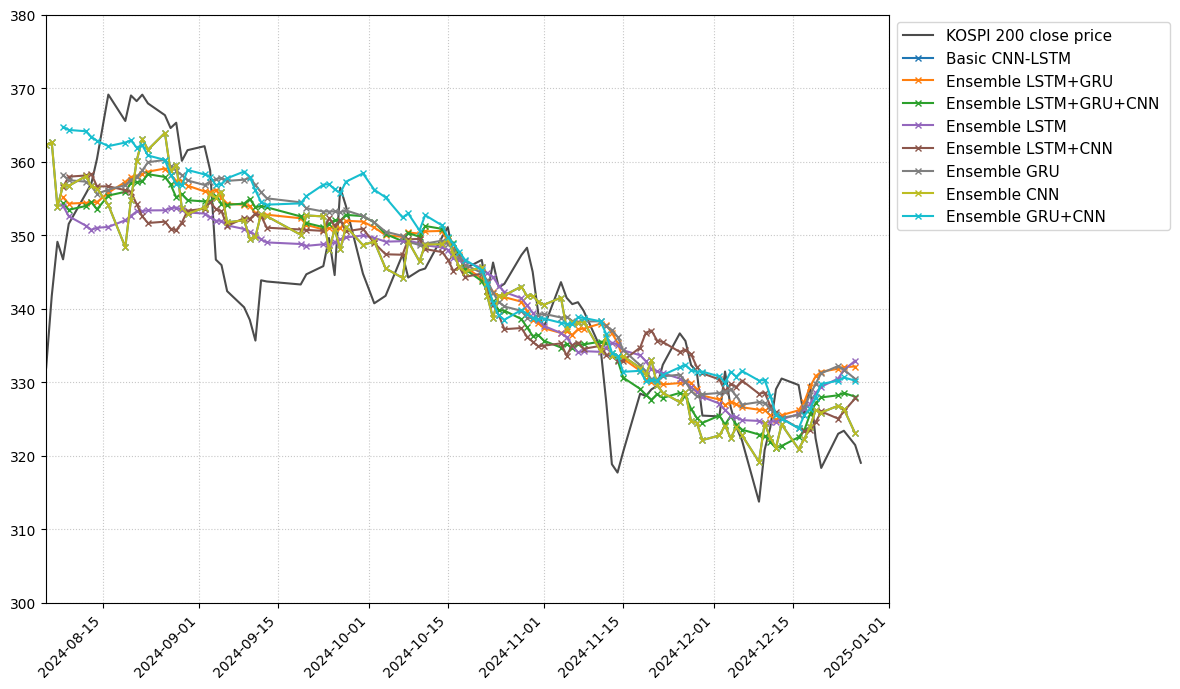

In [ ]:
warnings.filterwarnings("ignore")

colors = plt.cm.get_cmap('tab10', len(plotting_models_info))

plt.figure(figsize=(14, 7))

df_kospi_plot_date = pd.to_datetime(df_kospi['date'])
plt.plot(df_kospi_plot_date, df_kospi['closing price'],
         label='KOSPI 200 close price', color='black', alpha=0.7, linestyle='-')

for i, model_info in enumerate(plotting_models_info):
    model_data = model_info['var']
    model_label = model_info['label']
    current_color = colors(model_info['color_idx'])

    dates = pd.to_datetime(model_data['dates'])


    plt.plot(dates, model_data['y_pred'],
             label=f'{model_label} ',
             color=current_color, linestyle='-', marker='x', markersize=4)

start_date = pd.to_datetime('2024-08-05')
end_date = pd.to_datetime('2025-01-01')

plt.xlim(left=start_date)
plt.xlim(right=end_date)

plt.ylim(300,380)

plt.xticks(rotation=45, ha='right')
plt.legend(fontsize=11, loc='upper left', bbox_to_anchor=(1, 1))
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout(rect=[0, 0, 0.85, 1])

#Contusion matrix

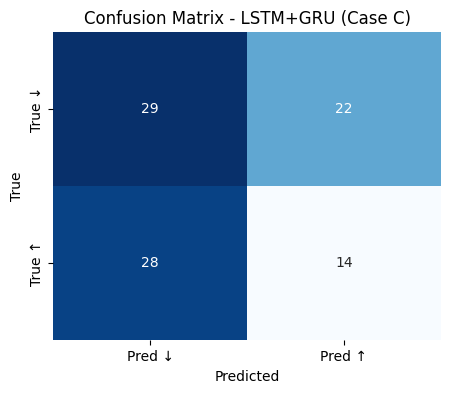

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# 예시: LSTM+GRU 모델 선택
model_df = df_ensemble[df_ensemble['ensemble_name'] == 'lstm+gru'].iloc[0]

# y_true, y_pred 꺼내오기
y_true = np.array(model_df['y_true'])
y_pred = np.array(model_df['y_pred'])

# 방향성 변환 (오늘 종가 > 어제 종가 → 1, 아니면 0)
# ※ 이미 y_true, y_pred가 "가격" 값이라 가정
true_direction = np.where(np.diff(y_true, prepend=y_true[0]) > 0, 1, 0)
pred_direction = np.where(np.diff(y_pred, prepend=y_pred[0]) > 0, 1, 0)

cm = confusion_matrix(true_direction, pred_direction)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Pred ↓", "Pred ↑"],
            yticklabels=["True ↓", "True ↑"])
plt.ylabel("True")
plt.xlabel("Predicted")
plt.title("Confusion Matrix - LSTM+GRU (Case C)")
plt.show()

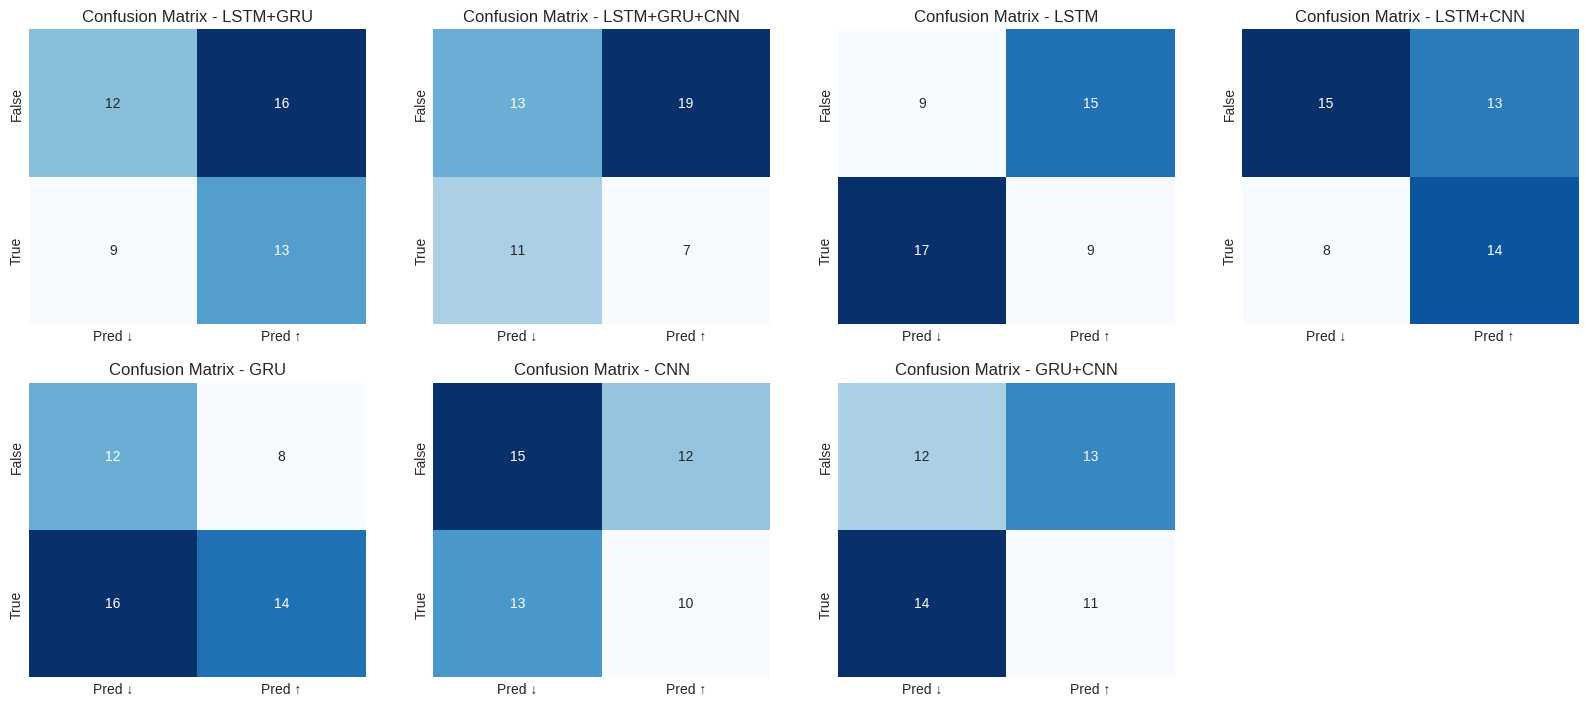

In [ ]:
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(20, 13))
axes = axes.flatten()
plt.style.use('seaborn-v0_8-whitegrid')

for i, model_name in enumerate(df_ensemble['ensemble_name'].unique()):
    if i >= len(axes):
        break

    model_df = df_ensemble[df_ensemble['ensemble_name'] == model_name].iloc[0]
    y_true = np.array(model_df['y_true'])
    y_pred = np.array(model_df['y_pred'])

    true_dir = np.where(np.diff(y_true, prepend=y_true[0]) > 0, 1, 0)
    pred_dir = np.where(np.diff(y_pred, prepend=y_pred[0]) > 0, 1, 0)

    cm = confusion_matrix(true_dir, pred_dir)

    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[i],
                xticklabels=["Pred ↓", "Pred ↑"],
                yticklabels=["False", "True"])
    axes[i].set_title(f'Confusion Matrix - {model_name.upper()}', fontsize=12)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)